# R les 3 opdrachten

In [1]:
install.packages("tidyverse")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [2]:
install.packages("nycflights13")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [3]:
library(tidyverse)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.0     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.2     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.1     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [4]:
library(nycflights13)

## Filteren

In [5]:
january_first_flights <- flights %>%
  filter(month == 1, day == 1)
print(january_first_flights)

# A tibble: 842 × 19
    year month   day dep_time sched_dep_time dep_delay arr_time sched_arr_time
   <int> <int> <int>    <int>          <int>     <dbl>    <int>          <int>
 1  2013     1     1      517            515         2      830            819
 2  2013     1     1      533            529         4      850            830
 3  2013     1     1      542            540         2      923            850
 4  2013     1     1      544            545        -1     1004           1022
 5  2013     1     1      554            600        -6      812            837
 6  2013     1     1      554            558        -4      740            728
 7  2013     1     1      555            600        -5      913            854
 8  2013     1     1      557            600        -3      709            723
 9  2013     1     1      557            600        -3      838            846
10  2013     1     1      558            600        -2      753            745
# ℹ 832 more rows
# ℹ 11 more v

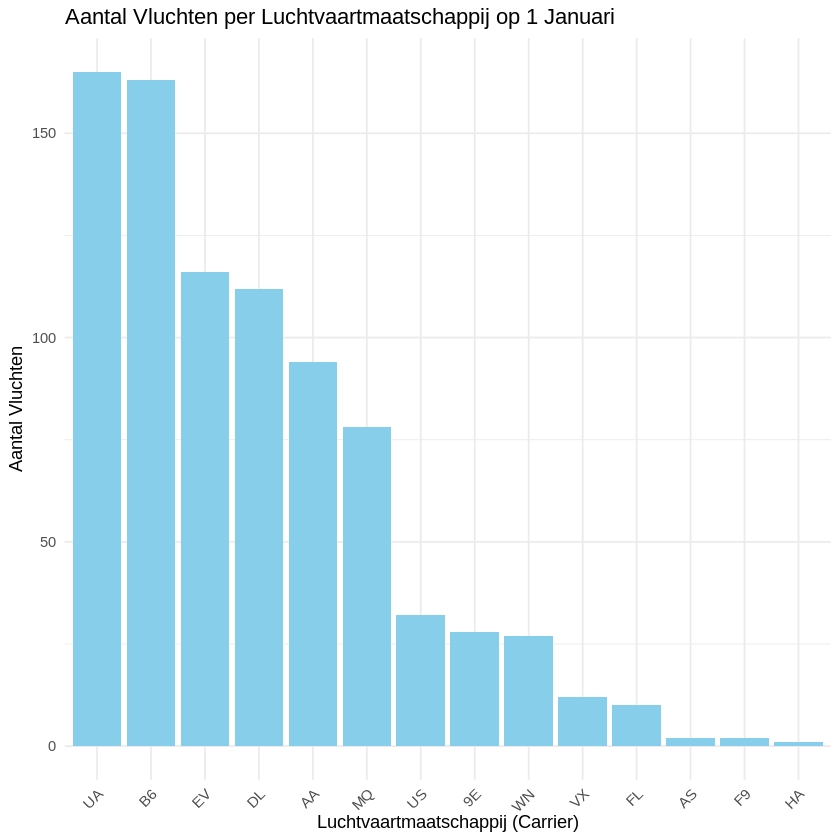

In [6]:
carrier_flights <- january_first_flights %>%
  group_by(carrier) %>%
  summarise(flight_count = n()) %>%
  arrange(desc(flight_count))

# Create the bar chart
ggplot(carrier_flights, aes(x = reorder(carrier, -flight_count), y = flight_count)) +
  geom_bar(stat = 'identity', fill = 'skyblue') +
  labs(title = 'Aantal Vluchten per Luchtvaartmaatschappij op 1 Januari',
       x = 'Luchtvaartmaatschappij (Carrier)',
       y = 'Aantal Vluchten') +
  theme_minimal() +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))


In [7]:
vakantie <- flights %>%
  filter(month %in% c(7, 8, 9))
print(vakantie)

# A tibble: 86,326 × 19
    year month   day dep_time sched_dep_time dep_delay arr_time sched_arr_time
   <int> <int> <int>    <int>          <int>     <dbl>    <int>          <int>
 1  2013     7     1        1           2029       212      236           2359
 2  2013     7     1        2           2359         3      344            344
 3  2013     7     1       29           2245       104      151              1
 4  2013     7     1       43           2130       193      322             14
 5  2013     7     1       44           2150       174      300            100
 6  2013     7     1       46           2051       235      304           2358
 7  2013     7     1       48           2001       287      308           2305
 8  2013     7     1       58           2155       183      335             43
 9  2013     7     1      100           2146       194      327             30
10  2013     7     1      100           2245       135      337            135
# ℹ 86,316 more rows
# ℹ 11 

## Ordenen

In [8]:
vakantie_gesorteerd <- vakantie %>%
  arrange(desc(dep_delay))
print(vakantie_gesorteerd)

# A tibble: 86,326 × 19
    year month   day dep_time sched_dep_time dep_delay arr_time sched_arr_time
   <int> <int> <int>    <int>          <int>     <dbl>    <int>          <int>
 1  2013     9    20     1139           1845      1014     1457           2210
 2  2013     7    22      845           1600      1005     1044           1815
 3  2013     7    22     2257            759       898      121           1026
 4  2013     9     2      606           1830       696      754           2040
 5  2013     7     7     2123           1030       653       17           1345
 6  2013     7    10     2334           1300       634       NA           1555
 7  2013     7     7     2059           1030       629      106           1350
 8  2013     9    12       12           1410       602      207           1635
 9  2013     9    12       33           1440       593      213           1642
10  2013     7     6      149           1600       589      456           1935
# ℹ 86,316 more rows
# ℹ 11 

In [9]:
top_5_delayed_carriers <- vakantie %>%
  group_by(carrier) %>%
  summarise(avg_dep_delay = mean(dep_delay, na.rm = TRUE)) %>%
  arrange(desc(avg_dep_delay)) %>%
  head(5)
print(top_5_delayed_carriers)


# A tibble: 5 × 2
  carrier avg_dep_delay
  <chr>           <dbl>
1 FL               27.1
2 F9               20.8
3 WN               20.3
4 9E               18.5
5 YV               17.9


In [10]:
airlines_data <- nycflights13::airlines

top_5_delayed_carriers_full_name <- top_5_delayed_carriers %>%
  left_join(airlines_data, by = "carrier") %>%
  select(carrier, name, avg_dep_delay) %>%
  arrange(desc(avg_dep_delay))

print(top_5_delayed_carriers_full_name)

# A tibble: 5 × 3
  carrier name                        avg_dep_delay
  <chr>   <chr>                               <dbl>
1 FL      AirTran Airways Corporation          27.1
2 F9      Frontier Airlines Inc.               20.8
3 WN      Southwest Airlines Co.               20.3
4 9E      Endeavor Air Inc.                    18.5
5 YV      Mesa Airlines Inc.                   17.9


## Selecteren

In [12]:
staartnummer <- flights %>%
  select(year, month, day, tailnum) %>%
  rename(tail_num = tailnum)

print(staartnummer)

# A tibble: 336,776 × 4
    year month   day tail_num
   <int> <int> <int> <chr>   
 1  2013     1     1 N14228  
 2  2013     1     1 N24211  
 3  2013     1     1 N619AA  
 4  2013     1     1 N804JB  
 5  2013     1     1 N668DN  
 6  2013     1     1 N39463  
 7  2013     1     1 N516JB  
 8  2013     1     1 N829AS  
 9  2013     1     1 N593JB  
10  2013     1     1 N3ALAA  
# ℹ 336,766 more rows


In [13]:
aantal_unieke_vliegtuigen <- staartnummer %>%
  summarise(unieke_tail_nums = n_distinct(tail_num))

print(aantal_unieke_vliegtuigen)

# A tibble: 1 × 1
  unieke_tail_nums
             <int>
1             4044


## Wijzigen

In [16]:
flights_sml <- flights %>%
  select(year, month, day, dep_delay, arr_delay, distance, air_time) %>%
  mutate(speed = distance / air_time*60)

print(flights_sml)

# A tibble: 336,776 × 8
    year month   day dep_delay arr_delay distance air_time speed
   <int> <int> <int>     <dbl>     <dbl>    <dbl>    <dbl> <dbl>
 1  2013     1     1         2        11     1400      227  370.
 2  2013     1     1         4        20     1416      227  374.
 3  2013     1     1         2        33     1089      160  408.
 4  2013     1     1        -1       -18     1576      183  517.
 5  2013     1     1        -6       -25      762      116  394.
 6  2013     1     1        -4        12      719      150  288.
 7  2013     1     1        -5        19     1065      158  404.
 8  2013     1     1        -3       -14      229       53  259.
 9  2013     1     1        -3        -8      944      140  405.
10  2013     1     1        -2         8      733      138  319.
# ℹ 336,766 more rows


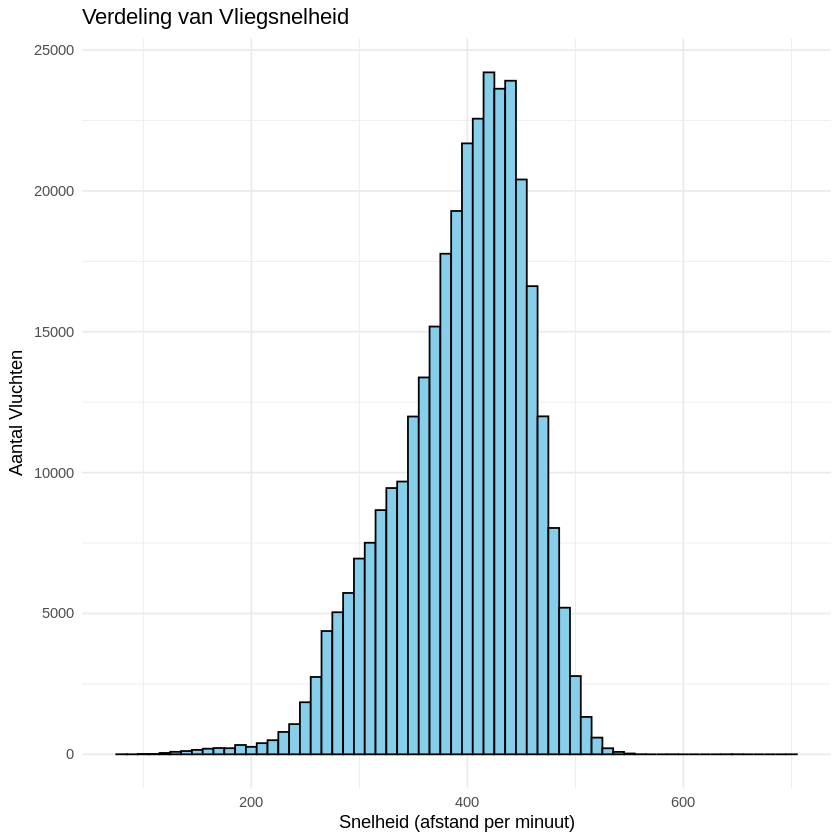

In [18]:
flights_sml %>%
  filter(!is.na(speed)) %>%
  ggplot(aes(x = speed)) +
  geom_histogram(binwidth = 10, fill = 'skyblue', color = 'black') +
  labs(title = 'Verdeling van Vliegsnelheid', x = 'Snelheid (afstand per minuut)', y = 'Aantal Vluchten') +
  theme_minimal()

## Samenvatten & groeperen

In [19]:
avg_dep_delay_2013 <- flights %>%
  summarise(gem_vert_vertraging = mean(dep_delay, na.rm = TRUE))

print(avg_dep_delay_2013)

# A tibble: 1 × 1
  gem_vert_vertraging
                <dbl>
1                12.6


In [20]:
avg_dep_delay_per_day_2013 <- flights %>%
  group_by(year, month, day) %>%
  summarise(gem_vert_vertraging_per_dag = mean(dep_delay, na.rm = TRUE)) %>%
  ungroup()

print(avg_dep_delay_per_day_2013)

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by year, month, and day.
ℹ Output is grouped by year and month.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(year, month, day))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.


# A tibble: 365 × 4
    year month   day gem_vert_vertraging_per_dag
   <int> <int> <int>                       <dbl>
 1  2013     1     1                       11.5 
 2  2013     1     2                       13.9 
 3  2013     1     3                       11.0 
 4  2013     1     4                        8.95
 5  2013     1     5                        5.73
 6  2013     1     6                        7.15
 7  2013     1     7                        5.42
 8  2013     1     8                        2.55
 9  2013     1     9                        2.28
10  2013     1    10                        2.84
# ℹ 355 more rows


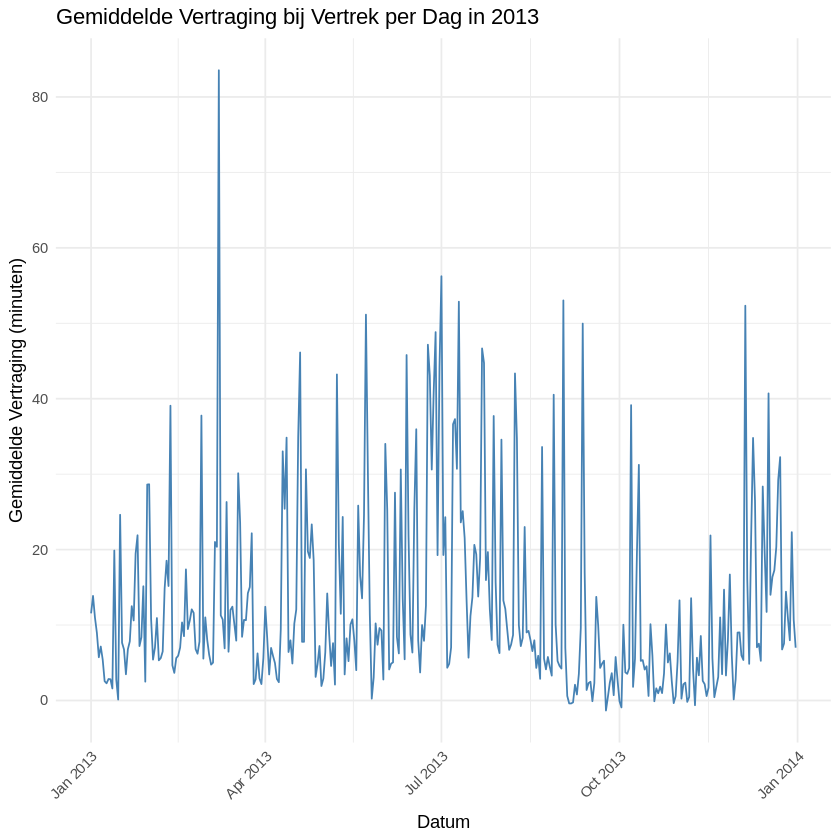

In [21]:
avg_dep_delay_per_day_2013 <- avg_dep_delay_per_day_2013 %>%
  mutate(date = make_date(year, month, day))

ggplot(avg_dep_delay_per_day_2013, aes(x = date, y = gem_vert_vertraging_per_dag)) +
  geom_line(color = 'steelblue') +
  labs(title = 'Gemiddelde Vertraging bij Vertrek per Dag in 2013',
       x = 'Datum',
       y = 'Gemiddelde Vertraging (minuten)') +
  theme_minimal() +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))

In [22]:
linear_model <- lm(gem_vert_vertraging_per_dag ~ date, data = avg_dep_delay_per_day_2013)
print(summary(linear_model))


Call:
lm(formula = gem_vert_vertraging_per_dag ~ date, data = avg_dep_delay_per_day_2013)

Residuals:
    Min      1Q  Median      3Q     Max 
-13.838  -8.283  -4.650   4.750  69.961 

Coefficients:
              Estimate Std. Error t value Pr(>|t|)
(Intercept) 130.655249  99.726469   1.310    0.191
date         -0.007423   0.006277  -1.183    0.238

Residual standard error: 12.64 on 363 degrees of freedom
Multiple R-squared:  0.003838,	Adjusted R-squared:  0.001094 
F-statistic: 1.399 on 1 and 363 DF,  p-value: 0.2377



I have successfully performed a linear regression to analyze the relationship between the date and the average daily departure delay. The summary of the linear model is as follows:

Coefficients:

Intercept: 130.655249
Date: -0.007423
P-value: The p-value for the date coefficient is 0.238, which is higher than the common significance level of 0.05. This suggests that there is no statistically significant linear relationship between the date and the average departure delay based on this model.

R-squared: The Multiple R-squared is 0.003838, meaning only about 0.38% of the variability in average departure delay can be explained by the date. The Adjusted R-squared is even lower at 0.001094.

`geom_smooth()` using formula = 'y ~ x'


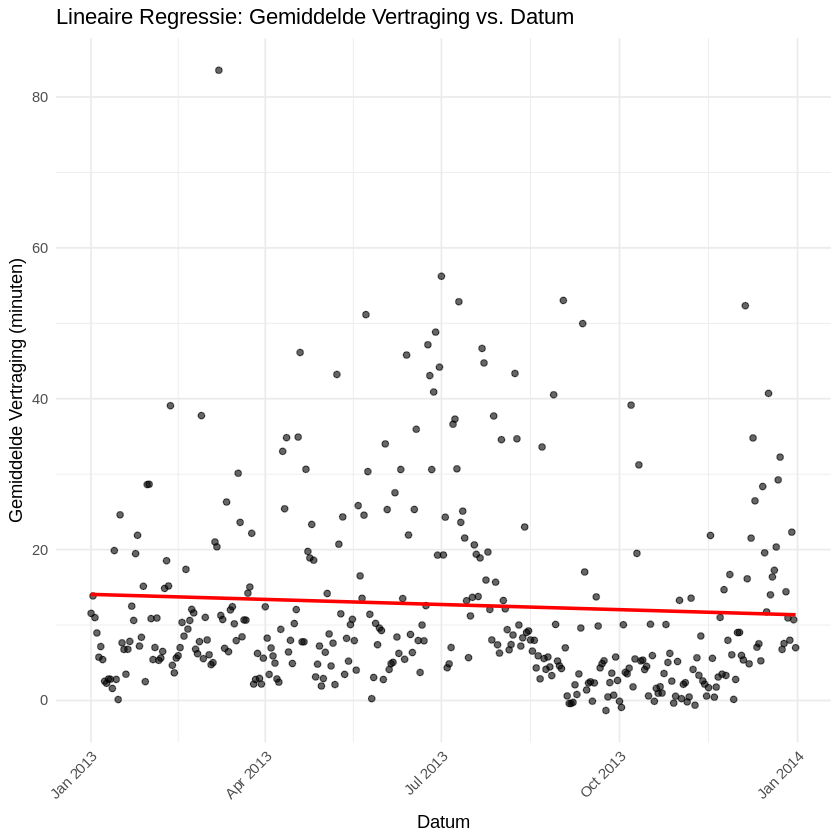

In [23]:
ggplot(avg_dep_delay_per_day_2013, aes(x = date, y = gem_vert_vertraging_per_dag)) +
  geom_point(alpha = 0.6) + # Add points for each day
  geom_smooth(method = 'lm', color = 'red', se = FALSE) + # Add the linear regression line
  labs(title = 'Lineaire Regressie: Gemiddelde Vertraging vs. Datum',
       x = 'Datum',
       y = 'Gemiddelde Vertraging (minuten)') +
  theme_minimal() +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))

In simpler terms, based on this linear regression, the date does not appear to be a strong predictor of the average daily departure delay in 2013. The visualization of this regression is shown in the plot above, where you can see the red line representing the linear fit among the scattered data points.